In [15]:
# Imports 
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# Load each CSV into a pandas DataFrame 
participants = pd.read_csv("participants_dummy.csv")
trials = pd.read_csv("trials_dummy.csv")
questionnaires = pd.read_csv("questionnaires_dummy.csv")

# Show the first few rows of each table to confirm the data loaded correctly.
print("PARTICIPANTS")
display(participants.head())

print("TRIALS")
display(trials.head())

print("QUESTIONNAIRES")
display(questionnaires.head())

In [ ]:
# Check the table sizes and column types to verify the dataset structure before cleaning.
print("Participants:", participants.shape)
print("Trials:", trials.shape)
print("Questionnaires:", questionnaires.shape)

print("\nParticipants data types:")
participants.info()

print("\nTrials data types:")
trials.info()

print("\nQuestionnaires data types:")
questionnaires.info()

In [ ]:
# Check for missing values in each table before analyzing or cleaning the data.
print("Missing values in Participants:")
print(participants.isnull().sum())

print("\nMissing values in Trials:")
print(trials.isnull().sum())

print("\nMissing values in Questionnaires:")
print(questionnaires.isnull().sum())

In [ ]:
# Look for repeated rows so we can confirm there are no duplicate records in the study data.
print("Duplicate records in Participants:",
      participants.duplicated().sum())

print("Duplicate records in Trials:",
      trials.duplicated().sum())

print("Duplicate records in Questionnaires:",
      questionnaires.duplicated().sum())

In [ ]:
# Validate that the raw survey values fall within the expected ranges and flag any outliers.
print("Invalid participant ages:")
display(participants[participants["age"] < 18])

print("Invalid NASA-TLX scores:")
tlx_columns = [
    "mental_demand",
    "physical_demand",
    "temporal_demand",
    "performance",
    "effort",
    "frustration"
]

display(questionnaires[
    (questionnaires[tlx_columns] < 0).any(axis=1) |
    (questionnaires[tlx_columns] > 100).any(axis=1)
])

print("Invalid UEQ-S responses:")
ueqs_columns = [
    col for col in questionnaires.columns
    if col.startswith("ueqs_item")
]

display(questionnaires[
    (questionnaires[ueqs_columns] < 1).any(axis=1) |
    (questionnaires[ueqs_columns] > 7).any(axis=1)
])

In [ ]:
# Data Preprocessing

In [ ]:
# Calculate the actual gameplay time by subtracting combat and cutscene pauses
trials["active_time_sec"] = (
    trials["elapsed_time_sec"] -
    trials["combat_cutscene_pause_sec"]
)

# Limit the completion time to a maximum of 480 seconds (8 minutes)
trials["completion_time_sec"] = trials["active_time_sec"].clip(upper=480)

# Display selected columns to check the calculated values
display(trials[[
    "participant_id",
    "condition",
    "elapsed_time_sec",
    "combat_cutscene_pause_sec",
    "active_time_sec",
    "completed",
    "completion_time_sec"
]])

In [ ]:
# List the six NASA-TLX subscales used to measure workload
tlx_columns = [
    "mental_demand",
    "physical_demand",
    "temporal_demand",
    "performance",
    "effort",
    "frustration"
]

# Calculate the unweighted average of the six subscales for each trial
questionnaires["nasa_tlx_raw"] = questionnaires[tlx_columns].mean(axis=1)

# Display the subscale scores and the calculated overall workload score
display(questionnaires[
    ["participant_id", "condition"] + tlx_columns + ["nasa_tlx_raw"]
])

In [ ]:

# Combine trial records with questionnaire responses
analysis_data = trials.merge(
    questionnaires,
    on=["participant_id", "condition"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check whether every trial has a matching questionnaire
print("Questionnaire matching results:")
print(analysis_data["_merge"].value_counts())

# Remove the temporary merge indicator column
analysis_data = analysis_data.drop(columns=["_merge"])

# Add participant background information
analysis_data = analysis_data.merge(
    participants,
    on="participant_id",
    how="left",
    validate="many_to_one"
)

# Display the combined dataset
print("Combined dataset:")
display(analysis_data.head())

# Check the number of rows and columns
print("Combined dataset shape:", analysis_data.shape)


In [ ]:
# Exploratory Data Analysis (EDA)

In [11]:

# Group gameplay records by guidance condition
performance_summary = analysis_data.groupby("condition").agg(
    # Calculate the average completion time
    average_completion_time=("completion_time_sec", "mean"),

    # Calculate the average number of wayfinding errors
    average_wayfinding_errors=("wayfinding_errors", "mean"),

    # Calculate the average number of lost episodes
    average_lost_episodes=("lost_episodes", "mean"),

    # Count the number of completed trials
    completed_trials=("completed", "sum"),

    # Count the total number of trials
    total_trials=("participant_id", "count")
).reset_index()

# Display the performance summary
display(performance_summary)


,condition,average_completion_time,average_wayfinding_errors,average_lost_episodes,completed_trials,total_trials
0,Explicit,193.125,0.625,0.000,8,8
1,Implicit,297.500,2.625,1.625,7,8


In [12]:

# Group questionnaire records by guidance condition
workload_summary = analysis_data.groupby("condition").agg(
    # Calculate the average overall NASA-TLX score
    average_workload=("nasa_tlx_raw", "mean"),

    # Calculate the average mental demand
    average_mental_demand=("mental_demand", "mean"),

    # Calculate the average physical demand
    average_physical_demand=("physical_demand", "mean"),

    # Calculate the average temporal demand
    average_temporal_demand=("temporal_demand", "mean"),

    # Calculate the average performance score
    average_performance=("performance", "mean"),

    # Calculate the average effort
    average_effort=("effort", "mean"),

    # Calculate the average frustration
    average_frustration=("frustration", "mean")
).reset_index()

# Display the workload summary
display(workload_summary)


,condition,average_workload,average_mental_demand,average_physical_demand,average_temporal_demand,average_performance,average_effort,average_frustration
0,Explicit,26.562500,33.75,20.0,28.75,27.500,33.750,15.625
1,Implicit,54.791667,63.75,32.5,60.00,54.375,68.125,50.000


In [13]:

# Group gameplay records by guidance condition
information_summary = analysis_data.groupby("condition").agg(
    # Calculate the average number of map openings
    average_map_openings=("map_openings", "mean"),

    # Calculate the average time spent viewing the map
    average_map_duration=("total_map_open_duration_sec", "mean"),

    # Calculate the average number of objective board openings
    average_objective_board_openings=("objective_board_openings", "mean")
).reset_index()

# Display the information usage summary
display(information_summary)


,condition,average_map_openings,average_map_duration,average_objective_board_openings
0,Explicit,1.875,33.625,1.25
1,Implicit,5.375,122.500,3.75


In [14]:

# Calculate descriptive statistics for participant background
background_summary = participants[
    ["age", "weekly_gaming_hours", "years_of_gaming"]
].describe()

# Display numerical summaries
print("Participant Background Summary:")
display(background_summary)

# Count participants by gender
print("Gender Distribution:")
display(participants["gender"].value_counts())

# Count participants by input device
print("Input Device Distribution:")
display(participants["input_device"].value_counts())

# Count participants by open-world gaming experience
print("Open-World Experience:")
display(participants["open_world_game_experience"].value_counts())


Participant Background Summary:


,age,weekly_gaming_hours,years_of_gaming
count,8.000000,8.000000,8.00000
mean,21.625000,8.875000,4.87500
std,1.407886,3.044316,2.03101
min,20.000000,5.000000,2.00000
25%,20.750000,6.750000,3.75000
50%,21.500000,8.500000,4.50000
75%,22.250000,10.500000,6.25000
max,24.000000,14.000000,8.00000


Gender Distribution:


gender
Woman    4
Man      4
Name: count, dtype: int64

Input Device Distribution:


input_device
Keyboard and mouse    4
Gamepad               4
Name: count, dtype: int64

Open-World Experience:


open_world_game_experience
Yes    8
Name: count, dtype: int64

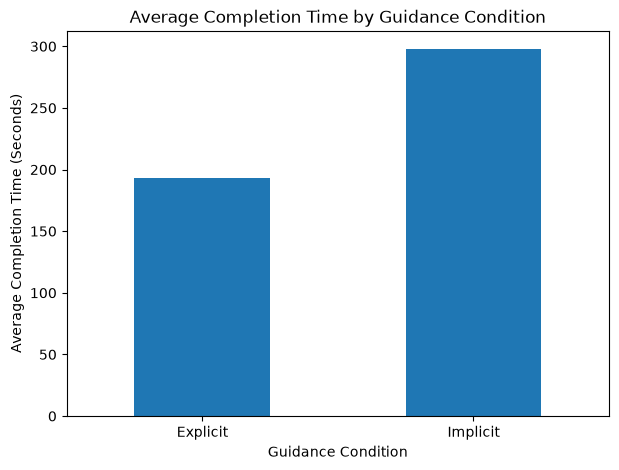

In [16]:
# Calculate average completion time for each condition
completion_summary = analysis_data.groupby("condition")[
    "completion_time_sec"
].mean()

# Create a bar chart
plt.figure(figsize=(7, 5))
completion_summary.plot(kind="bar")

# Add chart labels and title
plt.title("Average Completion Time by Guidance Condition")
plt.xlabel("Guidance Condition")
plt.ylabel("Average Completion Time (Seconds)")
plt.xticks(rotation=0)

# Display the chart
plt.show()

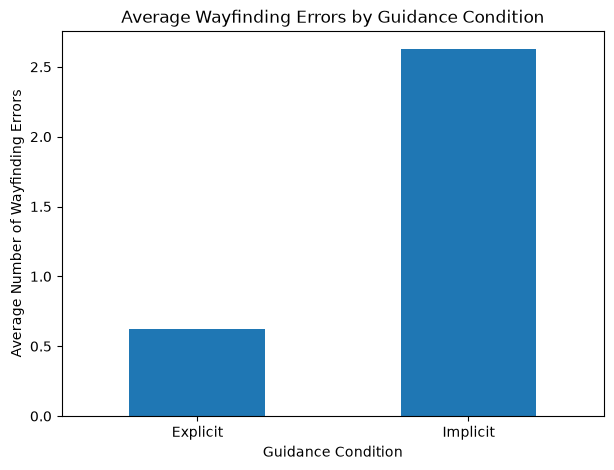

In [17]:
# Calculate the average number of wayfinding errors for each condition
error_summary = analysis_data.groupby("condition")[
    "wayfinding_errors"
].mean()

# Create a bar chart
plt.figure(figsize=(7, 5))
error_summary.plot(kind="bar")

# Add chart labels and title
plt.title("Average Wayfinding Errors by Guidance Condition")
plt.xlabel("Guidance Condition")
plt.ylabel("Average Number of Wayfinding Errors")
plt.xticks(rotation=0)

# Display the chart
plt.show()

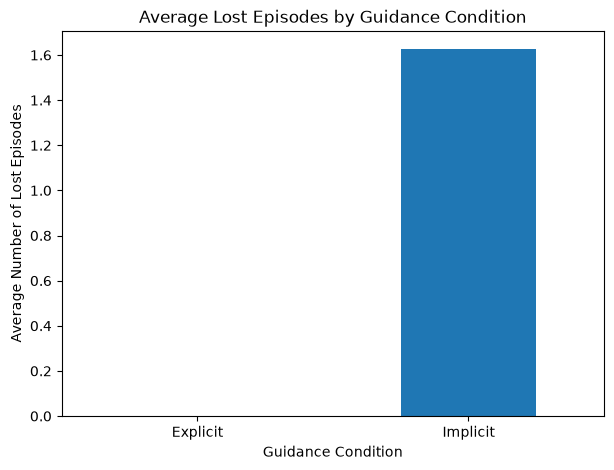

In [18]:
import matplotlib.pyplot as plt

# Calculate the average number of lost episodes for each condition
lost_summary = analysis_data.groupby("condition")[
    "lost_episodes"
].mean()

# Create a bar chart
plt.figure(figsize=(7, 5))
lost_summary.plot(kind="bar")

# Add chart labels and title
plt.title("Average Lost Episodes by Guidance Condition")
plt.xlabel("Guidance Condition")
plt.ylabel("Average Number of Lost Episodes")
plt.xticks(rotation=0)

# Display the chart
plt.show()

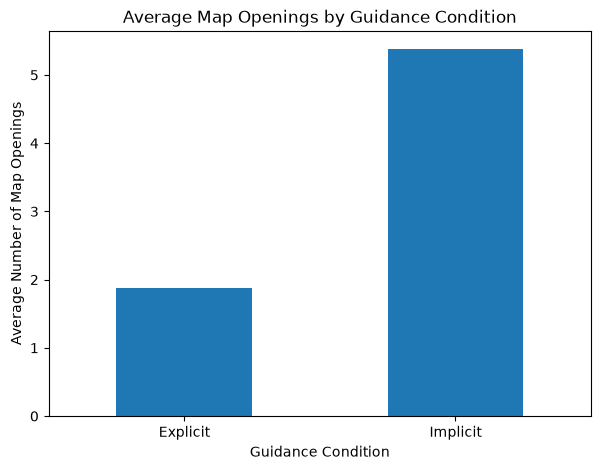

In [19]:
# Calculate the average number of map openings for each condition
map_summary = analysis_data.groupby("condition")[
    "map_openings"
].mean()

# Create a bar chart
plt.figure(figsize=(7, 5))
map_summary.plot(kind="bar")

# Add chart labels and title
plt.title("Average Map Openings by Guidance Condition")
plt.xlabel("Guidance Condition")
plt.ylabel("Average Number of Map Openings")
plt.xticks(rotation=0)

# Display the chart
plt.show()

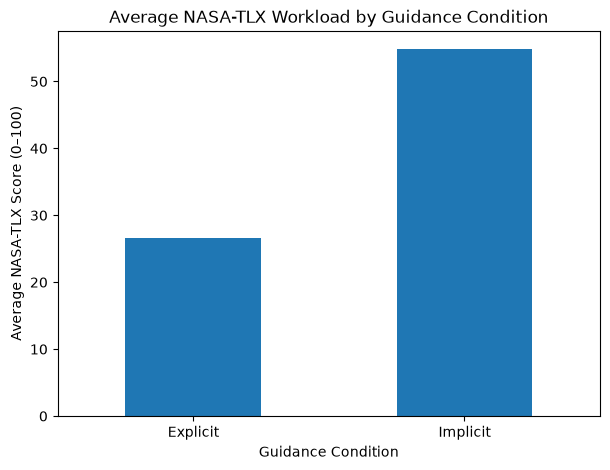

In [20]:
# Calculate the average NASA-TLX score for each condition
workload_chart = analysis_data.groupby("condition")[
    "nasa_tlx_raw"
].mean()

# Create a bar chart
plt.figure(figsize=(7, 5))
workload_chart.plot(kind="bar")

# Add chart labels and title
plt.title("Average NASA-TLX Workload by Guidance Condition")
plt.xlabel("Guidance Condition")
plt.ylabel("Average NASA-TLX Score (0–100)")
plt.xticks(rotation=0)

# Display the chart
plt.show()